# Листок 1
## СЛАУ, матрицы, квадратичные формы
Босарев Евгений Вадимович  
ЭФБО-11-24

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Math
from itertools import combinations, product
from math import comb
sp.init_printing()

def show(label, value):
    display(Math(label + ' = ' + sp.latex(value)))


## 1.1
Решение методом Гаусса: приведём расширенную матрицу к ступенчатому виду; свободная переменная $x_4=t$.

In [2]:
A = sp.Matrix([[1,5,-2,0],[-3,1,9,-5],[4,-8,-1,7]])
b = sp.Matrix([-7,9,0])
show(r'\operatorname{rref}(A|b)', A.row_join(b).rref()[0])
t = sp.symbols('t', real=True)
solution = A.gauss_jordan_solve(b)[0].subs({'tau0': t})
show('x', solution)
assert A*solution == b


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 1.2
После исключения ведущих переменных свободными остаются $x_3=s$, $x_4=t$.

In [3]:
A = sp.Matrix([[5,-1,5,9,-2],[3,0,6,9,-1],[2,0,4,6,-1]])
b = sp.Matrix([-3,4,0])
show(r'\operatorname{rref}(A|b)', A.row_join(b).rref()[0])
s, t = sp.symbols('s t', real=True)
solution = sp.Matrix([4-2*s-3*t,7-5*s-6*t,s,t,8])
show('x', solution)
assert A*solution == b


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 1.3
Переносим слагаемые с $x$ вправо. Матрица коэффициентов при $y,z,u$ обратима, поэтому они однозначно выражаются через $x$.

In [4]:
x = sp.symbols('x')
M = sp.Matrix([[97,90,48],[84,91,54],[18,21,13]])
show(r'\det M', M.det())
sol = M.inv() * (sp.Matrix([47,40,37])-x*sp.Matrix([32,35,17]))
show('y', sp.expand(sol[0]))
print('a =', sol[0].subs(x,0), '; b =', sp.diff(sol[0],x))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

a = 14027 ; b = -4262


## 1.4

In [5]:
A = sp.Matrix([[3,0,2],[0,1,3],[2,2,0],[0,1,0]])
B = sp.Matrix([[1,2,-1,2],[-2,-1,1,2],[2,1,1,2]])
C = sp.Matrix([[0,-4,6,1],[2,2,-5,-2],[2,-2,6,4],[1,3,0,1]])
show('AB+C', A*B+C)


<IPython.core.display.Math object>

## 1.5
а) Для $a_{ij}=\min(i,j)$ имеем $A=LL^T$, где $L$ — нижняя треугольная матрица из единиц. Поэтому $\det A=1$.

б) Для $a_{ij}=\max(i,j)$ вычтем предыдущую строку из следующей, начиная снизу. В строке $i\ge2$ остаются единицы в первых $i-1$ столбцах и нули далее. Разложение по последнему столбцу даёт $\det A=(-1)^{n-1}n$.

в) Для $D=(|i-j|)$ при $n\ge2$ разности соседних строк и затем соседних столбцов приводят к блоку: диагональ нижнего блока равна $-2$, остальные его элементы нулевые, первая строка и столбец вне угла состоят из единиц. По дополнению Шура
$$\det D=(-2)^{n-1}\left(0-\frac{n-1}{-2}\right)=(-1)^{n-1}(n-1)2^{n-2}.$$
При $n=1$ определитель равен нулю.

In [6]:
for n in range(1,7):
    matrices = [sp.Matrix(n,n,lambda i,j: min(i+1,j+1)),
                sp.Matrix(n,n,lambda i,j: max(i+1,j+1)),
                sp.Matrix(n,n,lambda i,j: abs(i-j))]
    print(n, [m.det() for m in matrices])


1 [1, 1, 0]
2 [1, -2, -1]
3 [1, 3, 4]
4 [1, -4, -12]
5 [1, 5, 32]
6 [1, -6, -80]


## 1.6
Определитель линеен по каждому элементу. Максимум его модуля на кубе $[-1,1]^{36}$ достигается в вершине, поэтому нули не увеличивают максимум.
Умножением строк и столбцов на $-1$ первую строку и первый столбец можно сделать единичными, сохранив модуль определителя. Оставшиеся пять строк выбираются из 31 варианта (строку из одних единиц исключаем). Повторные строки дают ноль, порядок строк меняет только знак. Достаточно проверить $\binom{31}{5}=169911$ матриц. Перебор ниже даёт максимум 160; перестановка строк позволяет выбрать положительный знак.

In [7]:
rows = np.array([r for r in product([-1,1], repeat=5) if r != (1,1,1,1,1)])
indices = np.array(list(combinations(range(31),5)))
best = 0
best_matrix = None
for start in range(0,len(indices),10000):
    block = indices[start:start+10000]
    matrices = np.ones((len(block),6,6), dtype=float)
    matrices[:,1:,1:] = rows[block]
    determinants = np.rint(np.linalg.det(matrices)).astype(int)
    k = np.argmax(abs(determinants))
    if abs(determinants[k]) > best:
        best = abs(determinants[k])
        best_matrix = matrices[k].astype(int)
print('Максимальный определитель:', best)
if sp.Matrix(best_matrix).det() < 0:
    best_matrix[[0,1]] = best_matrix[[1,0]]
show('A', sp.Matrix(best_matrix))
assert sp.Matrix(best_matrix).det() == 160


Максимальный определитель: 160


<IPython.core.display.Math object>

## 1.7
Матрица состоит из блока $B=\begin{pmatrix}d_1&0.57\\0.03&d_2\end{pmatrix}$ и диагонального хвоста. Поэтому
$$\det A=(d_1d_2-0.57\cdot0.03)\prod_{i=3}^n d_i,$$
$$\operatorname{tr}A^{-1}=\frac{d_1+d_2}{d_1d_2-0.57\cdot0.03}+\sum_{i=3}^n\frac1{d_i}.$$
Создавать массив $80000\times80000$ не требуется.

In [8]:
d = np.linspace(0.99,1.01,80000)
det_b = d[0]*d[1]-0.57*0.03
det_a = det_b*np.exp(np.log(d[2:]).sum())
trace_inverse = (d[0]+d[1])/det_b + (1/d[2:]).sum()
print(f'Определитель: {det_a:.9f}; след обратной: {trace_inverse:.9f}')


Определитель: 0.258979114; след обратной: 80002.702766086


## 1.8
Пусть $d_i=1.07^{(i-1)/(n-1)}$, $r_j=1+0.1(j-1)/(n-1)$. Обратная матрица имеет $b_{ii}=1/d_i$, $b_{1j}=-r_j/d_j$ при $j>1$, а остальные элементы нулевые.

In [9]:
n = 43000
d = 1.07**(np.arange(n)/(n-1))
r = np.linspace(1,1.10,n)
first_row = -r[1:]/d[1:]
print('Наименьший элемент:', first_row.min())
print('Сумма элементов:', (1/d).sum()+first_row.sum())


Наименьший элемент: -1.0280373831775702
Сумма элементов: -2054.438267008649


## 1.9
Спектральный радиус $A$ меньше единицы. Так как элементы $A$ положительны, суммы возрастают по $n$, а верхняя граница равна $B_k=(I-A)^{-1}A^k$. Проверяем наименьшее $k$ по этой границе.

In [10]:
A = 0.057*np.array([[7,14],[9,1]],dtype=float)
I = np.eye(2)
print('Спектральный радиус:', max(abs(np.linalg.eigvals(A))))
S = sum((np.linalg.matrix_power(A,i) for i in range(4,71)),np.zeros((2,2)))
B = np.linalg.solve(I-A,np.linalg.matrix_power(A,4))
k = 0
while np.linalg.solve(I-A,np.linalg.matrix_power(A,k)).max() >= 0.0002:
    k += 1
print('max S4,70 =',S.max(), '; max B4 =',B.max(), '; k =',k)


Спектральный радиус: 0.8902801522014684
max S4,70 = 3.609679030803459 ; max B4 = 3.611174678109661 ; k = 89


## 1.10

In [11]:
x = sp.symbols('x')
M = sp.Matrix([[7,5,5,x],[2,2,6,9],[3,x,8,0],[3,1,1,0]])
p = sp.Poly(M.det(),x)
show(r'\det M', p.as_expr())
print('a =',p.nth(2),'; b =',p.nth(1))


<IPython.core.display.Math object>

a = 16 ; b = -116


## 1.11
Строки и столбцы нумеруются с 1, как в условии; над диагональю стоят нули.

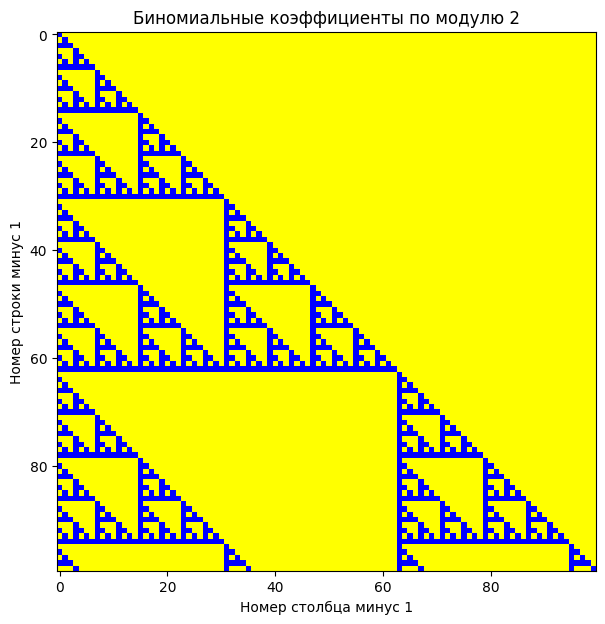

In [12]:
P = np.array([[comb(i,j)%2 if j<=i else 0 for j in range(1,101)]
              for i in range(1,101)])
plt.figure(figsize=(7,7))
plt.imshow(P,cmap=ListedColormap(['yellow','blue']),interpolation='nearest')
plt.xlabel('Номер столбца минус 1'); plt.ylabel('Номер строки минус 1')
plt.title('Биномиальные коэффициенты по модулю 2')
plt.show()


## 1.12
Используем построение Сильвестра: $H_1=(1)$, $H_2=\begin{pmatrix}1&1\\1&-1\end{pmatrix}$,
$$H_{2n}=H_2\otimes H_n=\begin{pmatrix}H_n&H_n\\H_n&-H_n\end{pmatrix}.$$
Если $H_nH_n^T=nI$, перемножение блоков даёт $H_{2n}H_{2n}^T=2nI$. Это доказывает утверждение по индукции. Порядок строк на рисунке может отличаться от примера.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

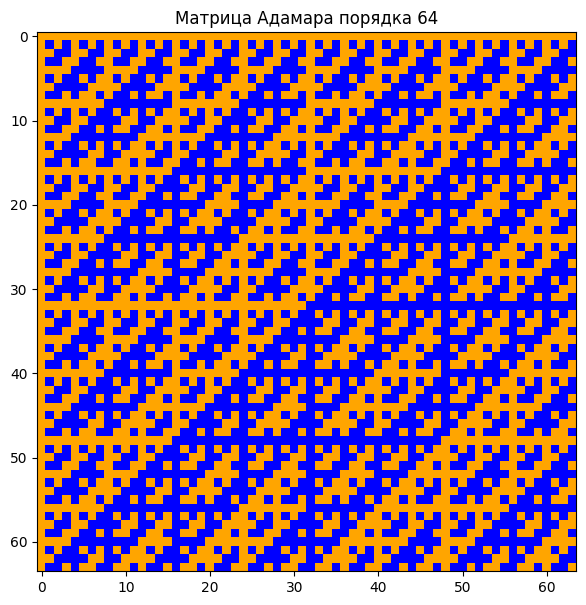

In [13]:
H2 = np.array([[1,1],[1,-1]])
show('H_1',sp.Matrix([[1]])); show('H_2',sp.Matrix(H2))
show('H_4',sp.Matrix(np.kron(H2,H2)))
H = np.array([[1]])
for _ in range(6):
    H = np.kron(H2,H)
assert np.array_equal(H@H.T,64*np.eye(64))
plt.figure(figsize=(7,7))
plt.imshow(H,cmap=ListedColormap(['blue','orange']),interpolation='nearest')
plt.title('Матрица Адамара порядка 64'); plt.show()


## 1.13
Находим собственные значения, выбираем значение с наибольшей мнимой частью и делим соответствующий вектор на первую координату.

In [14]:
A = np.array([[14,10,21],[12,15,26],[18,11,27]],dtype=float)
values,vectors = np.linalg.eig(A)
idx = np.argmax(values.imag)
z = values[idx]; vector = vectors[:,idx]/vectors[0,idx]
print('Z =',z,'; X =',vector)
print('Im Z =',z.imag,'; Re U =',vector[1].real)
assert np.allclose(A@vector,z*vector)


Z = (1.9688403308016502+0.3447893484271669j) ; X = [ 1.        -0.j          3.74781973+1.33084677j -2.35758843-0.61731802j]
Im Z = 0.3447893484271669 ; Re U = 3.747819729394814


## 1.14
Ищем первую линейную зависимость среди $I,A,A^2,\ldots$. Если степень минимальна, найденный аннулирующий многочлен является минимальным.

In [15]:
A = sp.Matrix([[-3,7,-6,-1,8,-3,-2],[1,-5,8,-3,-5,4,-5],
 [1,3,-4,6,-2,0,8],[-1,11,-12,9,3,-3,9],[-3,11,-12,5,8,-4,6],
 [-3,2,1,-4,4,1,-7],[1,-5,6,-2,-4,3,-2]])
columns = [sp.eye(7).reshape(49,1)]
for degree in range(1,8):
    power = A**degree
    basis = sp.Matrix.hstack(*columns)
    if basis.rank() == basis.row_join(power.reshape(49,1)).rank():
        coefficients = basis.gauss_jordan_solve(-power.reshape(49,1))[0]
        polynomial = x**degree+sum(coefficients[i]*x**i for i in range(degree))
        show('m_A(x)',sp.factor(polynomial))
        assert power+sum((coefficients[i]*A**i for i in range(degree)),sp.zeros(7)) == sp.zeros(7)
        break
    columns.append(power.reshape(49,1))


<IPython.core.display.Math object>

## 1.15
Собственные векторы симметричной матрицы ортогональны для разных собственных значений. Внутри кратного собственного подпространства используем ортогонализацию.

In [16]:
A = sp.Matrix([[17,-8,4],[-8,17,-4],[4,-4,11]])
vectors = []
for eigenvalue,multiplicity,basis in A.eigenvects():
    vectors.extend(sp.GramSchmidt(basis,True))
Q = sp.Matrix.hstack(*vectors)
show('Q',Q); show('Q^T A Q',sp.simplify(Q.T*A*Q))
assert sp.simplify(Q.T*Q)==sp.eye(3)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 1.16
Записываем $f=x^TAx$. Замена $x=Qy$ с ортогональной матрицей собственных векторов приводит форму к главным осям.

In [17]:
A = sp.Matrix([[3,4,0,0],[4,-3,0,0],[0,0,4,-2],[0,0,-2,1]])
vectors = []
for eigenvalue,multiplicity,basis in A.eigenvects():
    vectors.extend(sp.GramSchmidt(basis,True))
Q = sp.Matrix.hstack(*vectors)
show('Q',Q); show('D',sp.simplify(Q.T*A*Q))
assert sp.simplify(Q.T*Q)==sp.eye(4)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 1.17
Центр находится из $Ac=-b/2$. Затем $x=c+Qu$, где столбцы $Q$ — единичные собственные векторы квадратичной части.

In [18]:
for label,A,b,c0 in [('a',sp.Matrix([[5,2],[2,8]]),sp.Matrix([-32,-56]),80),
                     ('b',sp.Matrix([[5,6],[6,0]]),sp.Matrix([-22,-12]),-19)]:
    center = -A.inv()*b/2
    basis = [v/sp.sqrt(v.dot(v)) for _,_,vs in A.eigenvects() for v in vs]
    Q = sp.Matrix.hstack(*basis)
    D = sp.simplify(Q.T*A*Q)
    constant = sp.simplify((center.T*A*center)[0]+(b.T*center)[0]+c0)
    print(label); show('c',center); show('Q',Q); show('D',D)
    u,v = sp.symbols('u v')
    show('0',D[0,0]*u**2+D[1,1]*v**2+constant)
    print('Тип:', 'эллипс' if D.det()>0 else 'гипербола')


a


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Тип: эллипс
b


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Тип: гипербола


## 1.18
Положительная определённость невозможна при любом $\lambda$: на подпространстве $x_2=0$ значение при $(x_1,x_3)=(1,-1)$ равно $1+1-10=-8<0$.

## 1.19
По критерию Сильвестра для отрицательной определённости требуются $\Delta_1<0$, $\Delta_2>0$, $\Delta_3<0$.

In [19]:
lam = sp.symbols('lambda', real=True)
A = sp.Matrix([[lam,1,-1],[1,-2,1],[-1,1,-3]])
deltas = [A[:i,:i].det() for i in range(1,4)]
print('Угловые миноры:',deltas)
display(sp.reduce_inequalities([deltas[0]<0,deltas[1]>0,deltas[2]<0],lam))


Угловые миноры: [lambda, -2*lambda - 1, 5*lambda + 3]


## 1.20
В исходнике у $Q_2$ напечатано $2x_1$, без квадрата. Буквально это не квадратичная форма; линейная часть не исчезает при невырожденной линейной замене, поэтому с $Q_1$ такая функция не эквивалентна.
Если подразумевается $2x_1^2$, сравним инерции двух симметричных матриц. По закону инерции Сильвестра вещественные квадратичные формы эквивалентны тогда и только тогда, когда совпадает число положительных, отрицательных и нулевых квадратов.

In [20]:
matrices = [np.array([[2,4,-2],[4,9,-5],[-2,-5,3]],float),
            np.array([[2,-2,-2],[-2,3,4],[-2,4,6]],float)]
inertias = []
for A in matrices:
    eigenvalues = np.linalg.eigvalsh(A)
    inertia = (int(sum(eigenvalues>1e-9)),int(sum(eigenvalues < -1e-9)),
               int(sum(abs(eigenvalues)<=1e-9)))
    inertias.append(inertia)
    print('Собственные значения:',eigenvalues,'; инерция:',inertia)
print('При исправлении опечатки эквивалентны:',inertias[0]==inertias[1])


Собственные значения: [-1.91443056e-16  4.42561476e-01  1.35574385e+01] ; инерция: (2, 0, 1)
Собственные значения: [1.32913689e-15 1.22799813e+00 9.77200187e+00] ; инерция: (2, 0, 1)
При исправлении опечатки эквивалентны: True
